# Network Attack Detection using Machine Learning

**Dataset:** UNSW-NB15 (training and testing CSVs)

This notebook has three parts:

1. **Classification** – predict the attack type (`attack_cat`) with Logistic Regression, Decision Tree and Random Forest
2. **Regression** – predict a 0–10 severity score with Linear Regression and Random Forest Regressor
3. **Clustering** – group the traffic with K-Means (no labels) and compare the clusters with the real labels

**Running it:** works in **Google Colab** or locally with Jupyter. Just run all cells (*Runtime → Run all* in Colab).
The dataset (~47 MB) is downloaded automatically in the first cells. The whole notebook takes about 5–10 minutes on Colab.

## 0. Setup

In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             mean_squared_error, r2_score)

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
os.makedirs("models", exist_ok=True)

## 1. Load the data

The two official UNSW-NB15 CSVs are downloaded from a public mirror the first time you run this cell
(skipped if they are already in the `data/` folder).
Original source: [UNSW-NB15 dataset page](https://research.unsw.edu.au/projects/unsw-nb15-dataset).

In [ ]:
import urllib.request

BASE_URL = "https://huggingface.co/datasets/dileepa0011/unsw-nb15/resolve/main/"
os.makedirs("data", exist_ok=True)
for name in ["UNSW_NB15_training-set.csv", "UNSW_NB15_testing-set.csv"]:
    path = os.path.join("data", name)
    if not os.path.exists(path):
        print("Downloading", name, "...")
        urllib.request.urlretrieve(BASE_URL + name, path)
print("Data ready:", os.listdir("data"))

Data ready: ['UNSW_NB15_training-set.csv', 'UNSW_NB15_testing-set.csv']


In [ ]:
train = pd.read_csv("data/UNSW_NB15_training-set.csv")
test = pd.read_csv("data/UNSW_NB15_testing-set.csv")

print("Train shape:", train.shape)
print("Test shape: ", test.shape)
train.head()

Train shape: (175341, 45)
Test shape:  (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


### Class distribution
The dataset is **imbalanced**: lots of Normal and Generic traffic, very few Worms.

                train   test
attack_cat                  
Normal          56000  37000
Generic         40000  18871
Exploits        33393  11132
Fuzzers         18184   6062
DoS             12264   4089
Reconnaissance  10491   3496
Analysis         2000    677
Backdoor         1746    583
Shellcode        1133    378
Worms             130     44


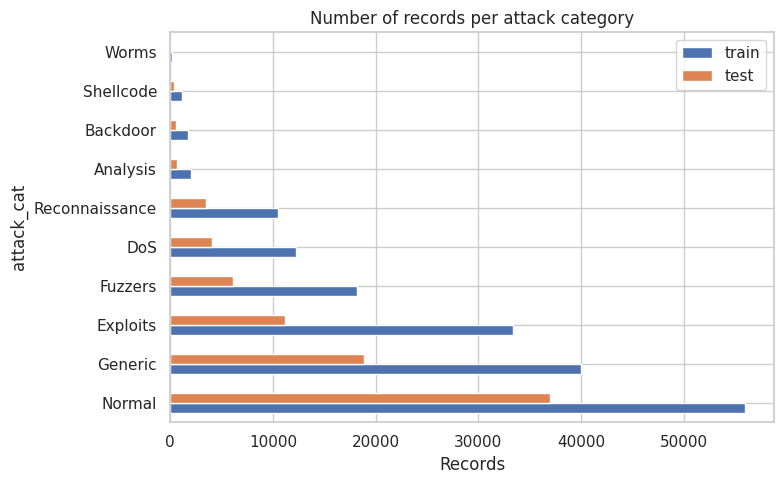

In [ ]:
counts = pd.DataFrame({"train": train["attack_cat"].value_counts(),
                       "test": test["attack_cat"].value_counts()})
print(counts)

counts.plot(kind="barh", figsize=(8, 5))
plt.title("Number of records per attack category")
plt.xlabel("Records")
plt.tight_layout()
plt.savefig("figures/class_distribution.png", dpi=120)
plt.show()

## 2. Preprocessing

- Drop `id` (just a row number).
- `attack_cat` is the classification target. `label` (0 = normal, 1 = attack) is kept aside for the clustering check.
- Encode the 3 text columns (`proto`, `service`, `state`) as numbers.
- Scale all features with `StandardScaler` (needed for Logistic Regression, Linear Regression and K-Means).

In [ ]:
print("Missing values:", train.isnull().sum().sum())

cat_cols = ["proto", "service", "state"]
feature_cols = [c for c in train.columns if c not in ["id", "attack_cat", "label"]]

X_train = train[feature_cols].copy()
X_test = test[feature_cols].copy()
y_train = train["attack_cat"]
y_test = test["attack_cat"]

# Text columns -> numbers. Values not seen in training become -1.
encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X_train[cat_cols] = encoder.fit_transform(X_train[cat_cols])
X_test[cat_cols] = encoder.transform(X_test[cat_cols])

# Scale features to mean 0, std 1
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Number of features:", len(feature_cols))

Missing values: 0
Number of features: 42


## 3. Part 1 – Classification (predict `attack_cat`)

We train three models and compare them on the test set using **accuracy** and **F1-score**.
- *Macro F1* treats every class equally (so rare classes like Worms count just as much).
- *Weighted F1* weights each class by how many records it has.

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "Weighted F1": f1_score(y_test, pred, average="weighted"),
    })
    print(f"{name} done")

results_df = pd.DataFrame(results).round(4)
results_df

Logistic Regression done
Decision Tree done
Random Forest done


,Model,Accuracy,Macro F1,Weighted F1
0,Logistic Regression,0.6717,0.3226,0.6777
1,Decision Tree,0.7329,0.4977,0.7613
2,Random Forest,0.7546,0.4751,0.7779


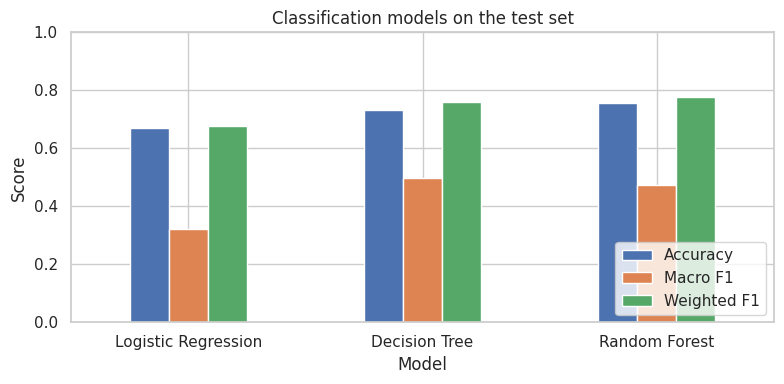

In [ ]:
results_df.set_index("Model").plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("Classification models on the test set")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/classification_comparison.png", dpi=120)
plt.show()

### Per-class report for the Random Forest

In [ ]:
print(classification_report(y_test, predictions["Random Forest"], digits=3))

                precision    recall  f1-score   support

      Analysis      0.006     0.012     0.008       677
      Backdoor      0.019     0.101     0.032       583
           DoS      0.615     0.118     0.199      4089
      Exploits      0.627     0.775     0.693     11132
       Fuzzers      0.293     0.583     0.390      6062
       Generic      0.998     0.971     0.985     18871
        Normal      0.963     0.757     0.847     37000
Reconnaissance      0.926     0.801     0.859      3496
     Shellcode      0.352     0.720     0.473       378
         Worms      0.500     0.182     0.267        44

      accuracy                          0.755     82332
     macro avg      0.530     0.502     0.475     82332
  weighted avg      0.840     0.755     0.778     82332



### Confusion matrices
Rows are the true class, columns the predicted class. Values are row percentages, so each row adds up to 100%.

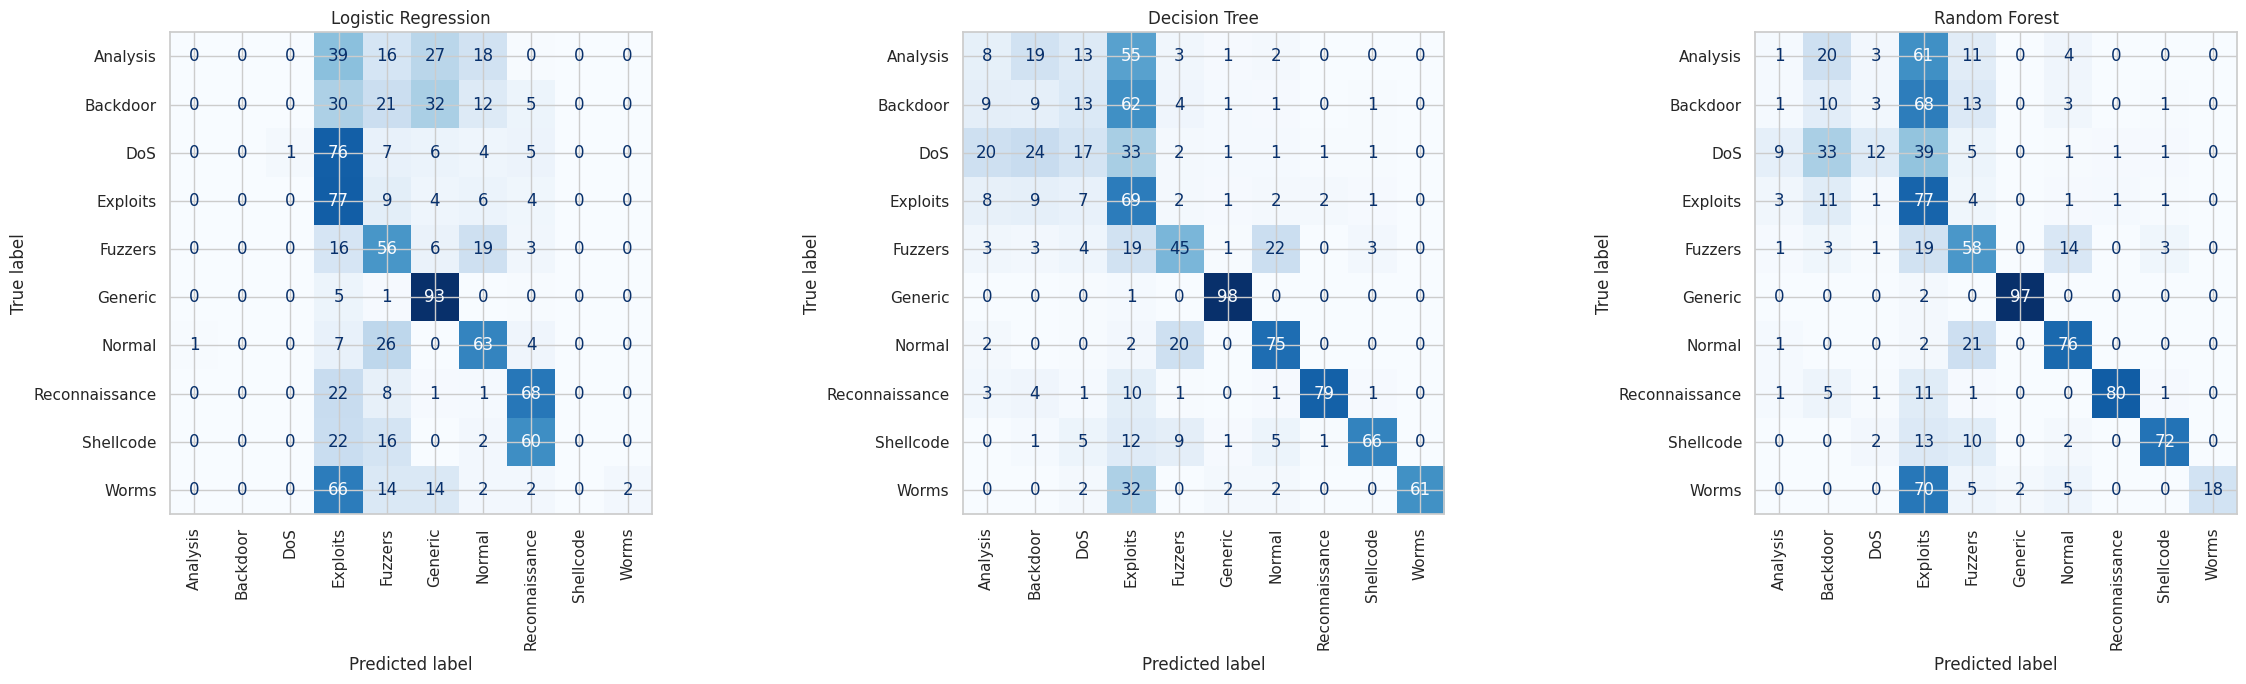

In [ ]:
classes = sorted(y_train.unique())
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, predictions[name], labels=classes, normalize="true") * 100
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(
        ax=ax, cmap="Blues", values_format=".0f", colorbar=False, xticks_rotation=90)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", dpi=110)
plt.show()

### Top 10 most important features (Random Forest)

sbytes              0.0763
ct_dst_sport_ltm    0.0705
sttl                0.0673
ct_dst_src_ltm      0.0643
ct_srv_dst          0.0550
smean               0.0514
ct_state_ttl        0.0460
ct_srv_src          0.0457
ct_src_dport_ltm    0.0411
dload               0.0355
dtype: float64


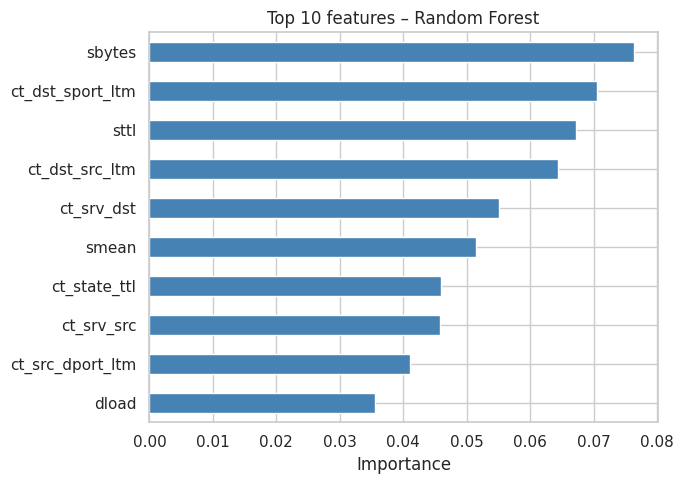

In [ ]:
rf = models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
top10 = importances.head(10)
print(top10.round(4))

top10.sort_values().plot(kind="barh", figsize=(7, 5), color="steelblue")
plt.title("Top 10 features – Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("figures/feature_importance.png", dpi=120)
plt.show()

### Save the Random Forest for the Streamlit app

In [ ]:
joblib.dump({"model": rf, "encoder": encoder, "scaler": scaler,
             "feature_cols": feature_cols, "cat_cols": cat_cols},
            "models/rf_classifier.joblib", compress=3)
print("Saved models/rf_classifier.joblib")

Saved models/rf_classifier.joblib


*On Colab:* files are deleted when the session ends. To use the model in the Streamlit app,
download it from the file panel on the left (`models/rf_classifier.joblib`) and put it in a `models/`
folder next to `app.py`.

## 4. Part 2 – Regression (predict a severity score)

We give each attack type a severity from 0 (harmless) to 10 (very dangerous) and predict that number.

In [ ]:
severity_map = {
    "Normal": 0,
    "Reconnaissance": 3,   # scanning / information gathering
    "Analysis": 4,         # probing, port scans, HTML penetration
    "Fuzzers": 5,          # sending random data to crash a service
    "Generic": 6,          # attacks against block ciphers
    "DoS": 7,              # making a service unavailable
    "Exploits": 8,         # using a known vulnerability
    "Shellcode": 8,        # code that gives control of the machine
    "Worms": 9,            # self-spreading malware
    "Backdoor": 9,         # hidden remote access
}
train["severity"] = train["attack_cat"].map(severity_map)
test["severity"] = test["attack_cat"].map(severity_map)
train[["attack_cat", "severity"]].drop_duplicates().sort_values("severity")

,attack_cat,severity
0,Normal,0
48866,Reconnaissance,3
47932,Analysis,4
48017,Fuzzers,5
117204,Generic,6
48999,DoS,7
48932,Exploits,8
48813,Shellcode,8
47911,Backdoor,9
49959,Worms,9


In [ ]:
y_train_sev = train["severity"]
y_test_sev = test["severity"]

reg_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1),
}

reg_results = []
reg_preds = {}
for name, model in reg_models.items():
    model.fit(X_train_s, y_train_sev)
    pred = model.predict(X_test_s)
    reg_preds[name] = pred
    reg_results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test_sev, pred)),
        "R2": r2_score(y_test_sev, pred),
    })

reg_df = pd.DataFrame(reg_results).round(4)
reg_df

,Model,RMSE,R2
0,Linear Regression,2.4356,0.4498
1,Random Forest Regressor,1.7352,0.7207


### Actual vs predicted severity
Each box shows the spread of predictions for one true severity level. A perfect model would put every box on the dashed line.

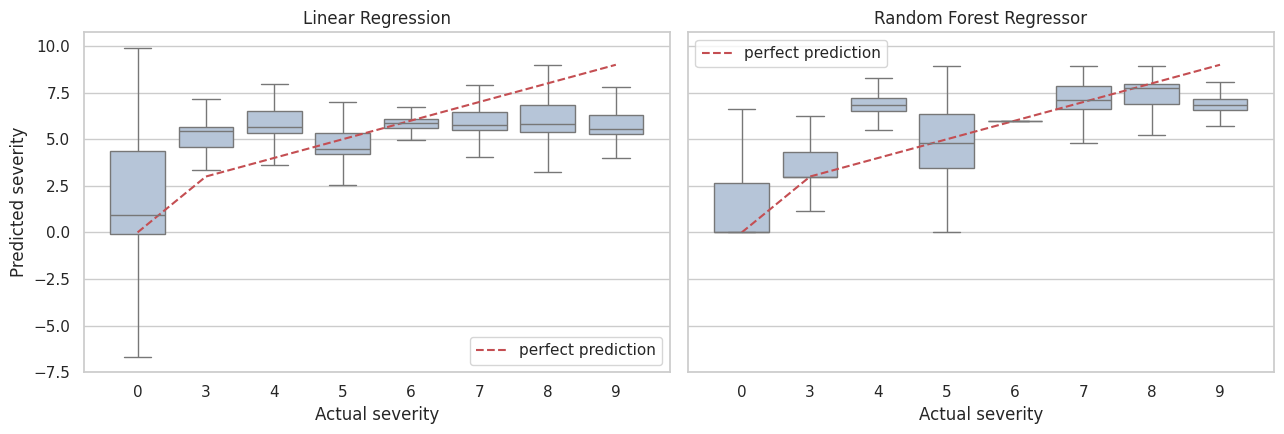

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, name in zip(axes, reg_models):
    sns.boxplot(x=y_test_sev, y=reg_preds[name], ax=ax, color="lightsteelblue", showfliers=False)
    levels = sorted(y_test_sev.unique())
    ax.plot(range(len(levels)), levels, "r--", label="perfect prediction")
    ax.set_title(name)
    ax.set_xlabel("Actual severity")
    ax.set_ylabel("Predicted severity")
    ax.legend()
plt.tight_layout()
plt.savefig("figures/regression_actual_vs_pred.png", dpi=120)
plt.show()

## 5. Part 3 – Clustering (K-Means, no labels)

We drop the labels, run K-Means on the scaled features, and then check whether
attacks and normal traffic end up in different clusters.

### Choosing k with the elbow method
We plot the *inertia* (total distance of points to their cluster centre) for k = 1…10
and look for the "elbow" where adding more clusters stops helping much.

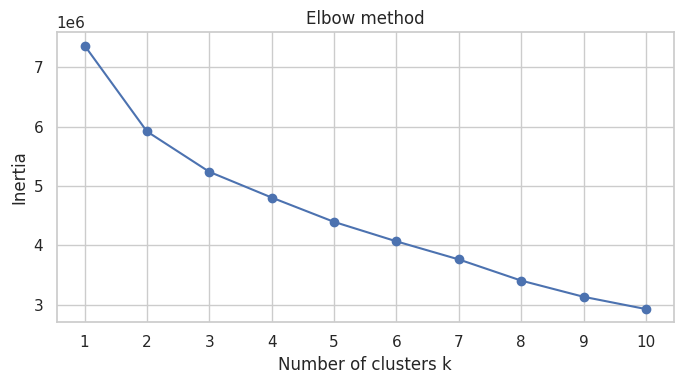

In [ ]:
inertias = []
k_values = range(1, 11)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_train_s)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_values, inertias, "o-")
plt.title("Elbow method")
plt.xlabel("Number of clusters k")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.tight_layout()
plt.savefig("figures/elbow.png", dpi=120)
plt.show()

### Fit K-Means with the chosen k
The curve drops steeply up to about k = 4. After that, each extra cluster only lowers the
inertia by a small, steady amount, so we pick **k = 4**.

In [ ]:
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_train_s)
pd.Series(clusters).value_counts().sort_index().rename("records per cluster")

,records per cluster
0,46835
1,49565
2,37528
3,41413


### 2D view with PCA
PCA squeezes the 42 features down to 2 so we can draw them. We plot a random sample of 10,000 points.

Variance explained by 2 components: 0.339


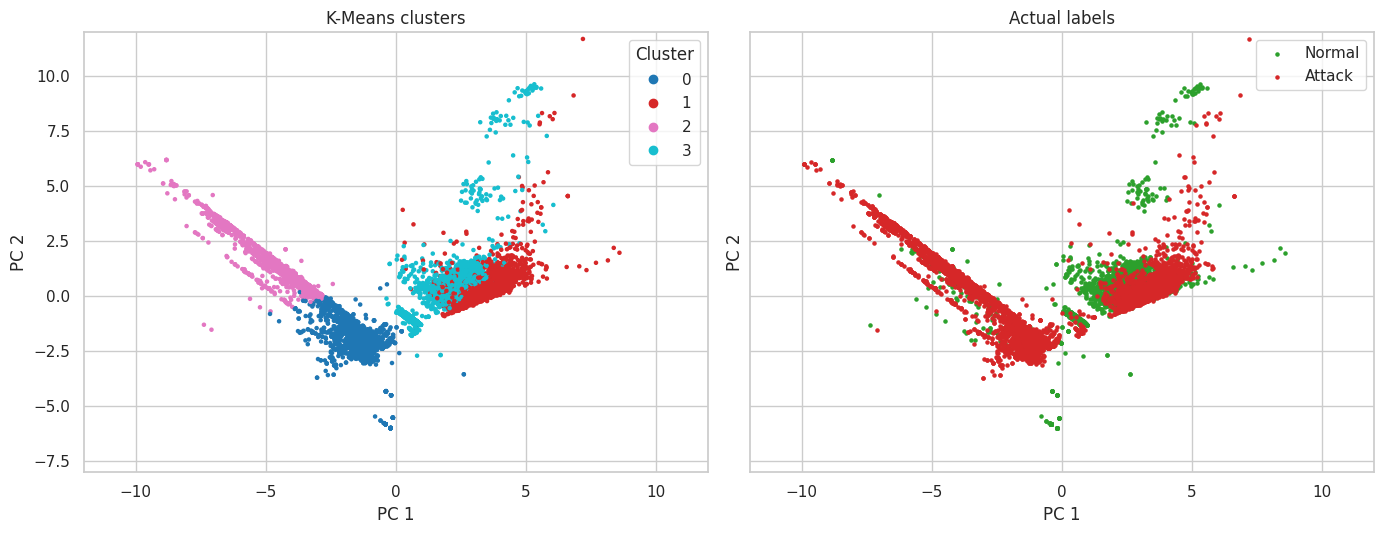

In [ ]:
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_train_s)
print("Variance explained by 2 components:", pca.explained_variance_ratio_.sum().round(3))

sample = np.random.RandomState(42).choice(len(X_2d), 10000, replace=False)
is_attack = train["label"].values[sample]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
sc = axes[0].scatter(X_2d[sample, 0], X_2d[sample, 1], c=clusters[sample], cmap="tab10", s=5)
axes[0].legend(*sc.legend_elements(), title="Cluster")
axes[0].set_title("K-Means clusters")

axes[1].scatter(X_2d[sample][is_attack == 0, 0], X_2d[sample][is_attack == 0, 1], s=5, c="tab:green", label="Normal")
axes[1].scatter(X_2d[sample][is_attack == 1, 0], X_2d[sample][is_attack == 1, 1], s=5, c="tab:red", label="Attack")
axes[1].legend()
axes[1].set_title("Actual labels")

for ax in axes:
    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")
    ax.set_xlim(-12, 12)   # zoom in: a few outliers lie far outside this range
    ax.set_ylim(-8, 12)
plt.tight_layout()
plt.savefig("figures/pca_clusters.png", dpi=120)
plt.show()

### Do attacks land in different clusters from normal traffic?

In [ ]:
ct_label = pd.crosstab(clusters, train["label"].map({0: "Normal", 1: "Attack"}),
                       rownames=["Cluster"], colnames=["Actual"])
ct_label["% attack"] = (100 * ct_label["Attack"] / ct_label.sum(axis=1)).round(1)
ct_label

Actual,Attack,Normal,% attack
Cluster,,,
0,41060,5775,87.7
1,39756,9809,80.2
2,36583,945,97.5
3,1942,39471,4.7


In [ ]:
pd.crosstab(clusters, train["attack_cat"], rownames=["Cluster"], colnames=["attack_cat"])

attack_cat,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
Cluster,,,,,,,,,,
0,1428,1417,9750,13206,5958,3368,5775,5343,575,15
1,564,272,2182,18769,11760,446,9809,5095,557,111
2,0,0,2,8,436,36131,945,5,1,0
3,8,57,330,1410,30,55,39471,48,0,4


## 6. Summary

| Part | Best model | Result on the test set |
|---|---|---|
| Classification | Random Forest | 75.5% accuracy, weighted F1 0.78 (Decision Tree has the best macro F1, 0.50) |
| Regression | Random Forest Regressor | RMSE 1.74, R² 0.72 (Linear Regression: RMSE 2.44, R² 0.45) |
| Clustering | K-Means, k = 4 | one cluster is 95% normal traffic, the other three are 80–98% attacks |

- Generic, Reconnaissance and Normal traffic are easy to recognise.
- DoS, Analysis and Backdoor are mostly confused with Exploits, because their traffic looks very similar.
- Even without labels, K-Means separates normal traffic from attacks quite well.